# Sentiment Predictions of Amazon Video Game Product Reviews using Regression Analysis
## Abigail Ma & Sky Shealy
## 25 November, 2026
Code Adapted from
https://github.com/handsOnLLM/Hands-On-Large-Language-Models/blob/main/chapter04/Chapter%204%20-%20Text%20Classification.ipynb

# Packages, Google Drive, and Reading Data

In [2]:
import json, random
import numpy as np
import pandas as pd
from google.colab import drive
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error
from sentence_transformers import SentenceTransformer

drive.mount('/content/drive', force_remount=True)
path = "/content/drive/MyDrive/DSA 495 Project/"
file = f"{path}Data/Video_Games.jsonl"


Mounted at /content/drive


# Sampling & Splitting

In [3]:
# sample
random.seed(495)
rows = []
with open(file, 'r') as fp:
    for line in fp:
        if random.random() < 0.005:
            rows.append(json.loads(line))

df = pd.DataFrame(rows)
df = df[["rating", "title", "text"]]

# clean + combine
def make_text(d):
    body = d["text"].fillna("").str.replace(r"<br\s*/?>", " ", regex=True)
    return (d["title"].fillna("") + ". " + body).str.replace(r"\s+", " ", regex=True).str.strip()

df["review"] = make_text(df)

# split
train_df, valid_test_df = train_test_split(df, test_size=0.3, random_state=42)
valid_df, test_df = train_test_split(valid_test_df, test_size=0.5, random_state=42)

# Embeddings & Ridge Regression
Compared to OLS, ridge regression shrinks the weight, using L2-Norm, on patterns that barely vary across reviews, because those are where OLS estimates are least stable. Patterns that vary a lot across reviews are mostly left alone, so they carry relatively more weight in the model.

In [4]:
# embed
model = SentenceTransformer("sentence-transformers/all-mpnet-base-v2")
X_train = model.encode(train_df["review"].tolist(), batch_size=64, show_progress_bar=True)
X_valid = model.encode(valid_df["review"].tolist(), batch_size=64, show_progress_bar=True)
X_test  = model.encode(test_df["review"].tolist(),  batch_size=64, show_progress_bar=True)

y_train, y_valid, y_test = train_df["rating"].values, valid_df["rating"].values, test_df["rating"].values

# baseline & alpha sweep
print("Baseline Predicting Mean; MSE:", mean_squared_error(y_valid, np.full_like(y_valid, y_train.mean())))
for a in [0, 0.001, 0.01, 0.1, 1, 10, 100]:
    pred = np.clip(Ridge(alpha=a).fit(X_train, y_train).predict(X_valid), 1, 5)
    print(a, mean_squared_error(y_valid, pred))

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/11.6k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/571 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

... (7 outputs left out)

Batches:   0%|          | 0/253 [00:00<?, ?it/s]

Batches:   0%|          | 0/55 [00:00<?, ?it/s]

Batches:   0%|          | 0/55 [00:00<?, ?it/s]

Baseline Predicting Mean; MSE: 2.1119432502192805
0 0.6483168742307086
0.001 0.6481427984582795
0.01 0.6477366394835771
0.1 0.6468407270243975
1 0.6593058874396864
10 0.7396745387455853
100 1.0073330609774949


Alpha = 0.1 gave the lowest validation MSE (0.647, RMSE = ~0.80), but ridge improved only marginally over OLS (0.648), so regularization isn't doing much with this sample size. Both are far better than the mean baseline (2.11).

Although moving forward with OLS produce unbiased beta coefficients compared to ridge, the interpretation of the coefficients is not the goal here. We use ridge with alpha = 0.1 because it achieved the lowest validation MSE and stabilizes the coefficients against correlated embedding dimensions, even though the improvement over OLS is small.

The `1` and `5` in `pred = np.clip(Ridge(alpha=a).fit(X_train, y_train).predict(X_valid), 1, 5)` mean that the model is clipping predictions below 1 to equal 1 and above 5 to equal 5. This is because there are no reviews outside of that range, and the model is not confined to be in that range.

In [8]:
best_alpha = 0.1

# score on test once
ridge = Ridge(alpha=best_alpha).fit(X_train, y_train)
test_pred = np.clip(ridge.predict(X_test), 1, 5)

test_mse = mean_squared_error(y_test, test_pred)
test_rmse = np.sqrt(test_mse)

# baseline on test for comparison (still uses train mean)
base_mse = mean_squared_error(y_test, np.full_like(y_test, y_train.mean()))

print(f"Test MSE:  {test_mse:.4f}")
print(f"Test RMSE: {test_rmse:.4f}")
print(f"Mean-baseline MSE: {base_mse:.4f} (RMSE = {np.sqrt(base_mse):.4f})")
print(f"R^2: {1 - test_mse / base_mse:.3f}")

Test MSE:  0.6143
Test RMSE: 0.7838
Mean-baseline MSE: 1.9806 (RMSE = 1.4073)
R^2: 0.690


- With an R^2 of 0.690, the model explains 69% of the variance in the data.
- - The model's predictions are typically off from the true rating by about 0.78 stars (RMSE), compared to 1.41 stars for the baseline that always predicts the mean rating.


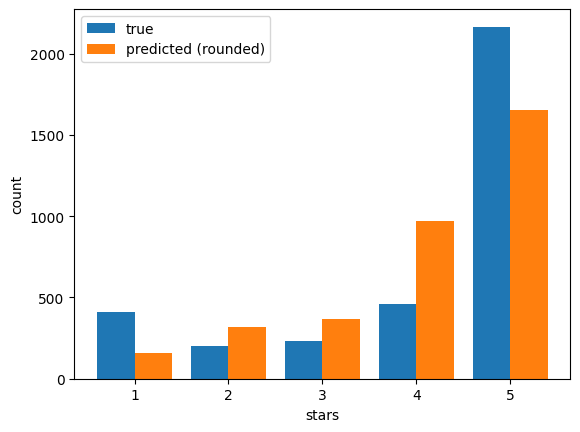

              precision    recall  f1-score   support

           1      0.785     0.303     0.437       409
           2      0.256     0.399     0.312       203
           3      0.256     0.403     0.313       233
           4      0.236     0.501     0.321       457
           5      0.896     0.685     0.776      2166

    accuracy                          0.580      3468
   macro avg      0.486     0.458     0.432      3468
weighted avg      0.715     0.580     0.618      3468

[[ 124  177   85   22    1]
 [  24   81   74   21    3]
 [   5   35   94   85   14]
 [   1   18   55  229  154]
 [   4    5   59  615 1483]]
Within 1 star: 0.9313725490196079
5 star vs rest: ROC-AUC 0.890, PR-AUC 0.913 (positive rate 0.625)
1 star vs rest: ROC-AUC 0.955, PR-AUC 0.705 (positive rate 0.118)
positive (4-5) vs negative (1-2), 3 dropped: ROC-AUC 0.979, PR-AUC 0.994 (positive rate 0.811)


In [10]:
import matplotlib.pyplot as plt
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score,
                             average_precision_score)

y_true = y_test.astype(int)
y_hat = np.rint(test_pred).astype(int)

# histograms
plt.hist([y_true, y_hat], bins=np.arange(0.5, 6.5, 1), label=["true", "predicted (rounded)"])
plt.xlabel("stars"); plt.ylabel("count"); plt.legend(); plt.show()

# multiclass metrics on rounded predictions
print(classification_report(y_true, y_hat, digits=3, zero_division=0))
print(confusion_matrix(y_true, y_hat, labels=[1, 2, 3, 4, 5]))
print("Within 1 star:", np.mean(np.abs(y_true - y_hat) <= 1))

# binary AUC / PR-AUC using the raw (unclipped) prediction as the score
raw = ridge.predict(X_test)
mask = y_true != 3
tasks = {
    "5 star vs rest":         (y_true == 5, raw, np.ones_like(y_true, bool)),
    "1 star vs rest":         (y_true == 1, -raw, np.ones_like(y_true, bool)),
    "positive (4-5) vs negative (1-2) w/ 3 dropped": (y_true >= 4, raw, mask),
}
for name, (y_bin, score, m) in tasks.items():
    yb, s = y_bin[m], score[m]
    print(f"{name}: ROC-AUC {roc_auc_score(yb, s):.3f}, "
          f"PR-AUC {average_precision_score(yb, s):.3f} (positive rate {yb.mean():.3f})")

## Model Performance
- Rounded accuracy is only 58%, but 93% of predictions are within one star. Most misses is a neighboring star and not a completely wrong sentiment analysis.
- Macro F1 (0.43) is well below weighted F1 (0.62) because 5 stars are 62% of the data and the model is good at them. The middle ratings drag the macro average down.

## Precision Metrics
- The middle reviews have precisions < 0.3, which is very low compared to 0.8 and 0.9 for 1 and 5 star reviews.
- The model predicts 4 stars more than twice as often as it actually showed up (972 vs 457). Most of that is 615 true 5s landing on 4, which is the main issue with using classification metrics on rounded numerical regression.
- The 1-star class has high precision (0.785) but low recall (0.303). When the model says 1, it's usually right, but it often says 2 for a true 1 (177 of 409).

## Binary AUCs

The model performance is better than the rounded labels suggest. Positive (4-5) vs negative (1-2) has ROC-AUC 0.979 and PR-AUC 0.994, so the model almost always puts a positive review above a negative one.
1 star vs rest has ROC-AUC 0.955. Its PR-AUC of 0.705 looks lower but is about 6x the positive rate (0.118), so it's a large increase over the positive ratings.
5 star vs rest is the weakest ranking (ROC-AUC 0.890). Separating 5 from 4 is difficult.
Low recall but high AUC suggests that the rounding feature is what is hurting the classification metrics the most.



# Looking at individual reviews

In [12]:
pd.set_option("display.max_colwidth", 300)

ex = test_df[["rating", "review"]].reset_index(drop=True)
ex["pred"] = test_pred.round(2)
ex["err"] = ex["pred"] - ex["rating"]   # positive = overpredicted
ex["pred_star"] = np.rint(ex["pred"]).astype(int)

def show(d, n=8, title=""):
    print(f"\n===== {title} =====")
    for _, r in d.head(n).iterrows():
        print(f"true {r.rating:.0f} | pred {r.pred:.2f} | {r.review[:300]}\n")

show(ex.sort_values("err", ascending=False), title="Most overpredicted (pred too high)")
show(ex.sort_values("err"), title="Most underpredicted (pred too low)")
show(ex[(ex.rating == 5) & (ex.pred_star == 4)].sample(8, random_state=1), title="True 5, predicted 4")
show(ex[(ex.rating == 1) & (ex.pred_star == 2)].sample(8, random_state=1), title="True 1, predicted 2")


===== Most overpredicted (pred too high) =====
true 1 | pred 5.00 | what ever. what ever

true 1 | pred 4.26 | Christmas gift. I got it for my boyfriend and it broke the first time he used it lol. It’s what he asked for so I had high hopes on it.

true 1 | pred 4.23 | Metal plate is awsome so is the ability to minimize everything at once... what good is it if the lazer-sensor is faulty though?. This mouse is not very good. Keep in mind it forces you to use its OWN functionality, not the functionality you would prefer.......... such as if you have the mouse set to

true 1 | pred 4.06 | NOT INSTANT..UNLESS YOU CAN TRAVEL INTO THE FUTURE. If I could give this 0 stars I would. This IS NOT INSTANT AT ALL. The people who said they got it instantly must have a time travel machine and traveled 2 days in the future. The few reviews I have seen on here that also didnt get it instantly are 

true 1 | pred 4.04 | Not for iPhone 14 Pro.. This product is not for the iPhone 14 Pro line, and doesn't 